In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
import gsw
from glob import glob
import matplotlib.patches as patches

import matplotlib.ticker as tkr
from matplotlib.lines import Line2D
from tqdm import tqdm
from datetime import datetime
import matplotlib.font_manager as fm


from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [3]:
def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

In [4]:
ref_depth = 50
target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)
zoomed_extent= [-48, -34, -30, -16] # [-45, -39, -27, -22]

datadir = '../data/glorys'

flist = sorted(glob(f"{datadir}/smax_*.nc"))
len(flist)

5

In [5]:
bathy = xr.open_dataset('../data/gebco_updated.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [6]:
dsall = xr.open_mfdataset(flist)

# cutting a very specific period after an analysis using the entire period
period = ['2022-02-04', '2022-03-27']
dsall = dsall.sel(time=slice(period[0], period[1]))

dsall.dims

Frozen({'depth': 23, 'latitude': 229, 'longitude': 265, 'time': 52})

In [7]:
# load the selected profiles for reference
import sys
sys.path.insert(0, '/home/danilo/phd/thesis/chapter_colab/scripts/')
from load_profiles import load_vertical_profiles

dict_casts = load_vertical_profiles()

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [8]:
# locations for the glorys ts diagram and the train profiles
locs_glorys = {
    '2022-02-04': [-41, - 25.3], # OK
    # '2022-02-13': [-41.8, -26], # REMOVER?
    '2022-02-11': [-41.1, -25.5], # OK
    '2022-02-22': [-41.3, -26.8], # ok
    '2022-02-26': [-42.8, -26], # ok
    '2022-03-12': [-43, -25.2], # ok
    '2022-03-20': [-43.2, -24.5], # ok
    '2022-03-27': [-43., -24.] # ok
}


In [9]:
def tsDiagram(fig=None,ax=None,
              si=np.arange(32,38.3,0.2),
              ti=np.arange(10,259,0.2),
              figsize=(10,6),rainbow=False,
              xlim=[32.5, 37.5],
              ylim=[10,30],
              text=True, lang='en',
              xlabel=True,
              ylabel=True):
    """
     import parametric isopicnals
     plot patches for each water mass, based on values found in config.py
     plot legend for
    """
    if not fig:
        fig, ax = plt.subplots(figsize=figsize)

    # parametric isopicnals to be used as background contour
    # si, ti, sigma0 = parametric_isopicnal()
    sm,ym = np.meshgrid(si, ti)
    sigma0 = gsw.sigma0(sm,ym)
   
    levels = np.arange(0, 40, 0.5)
    CS = ax.contour(si, ti, sigma0, levels, linestyles='dashed', colors='k', alpha=.3, linewidths=(0.5))
    ax.clabel(CS,  fontsize=12, fmt='%1.1f', inline=1, inline_spacing=0)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    # specific values
    CS = ax.contour(si, ti, sigma0, [24.6, 25.6], linestyles='dashed', colors='r', alpha=.3, linewidths=(1.))
    if lang == 'pt':
        ax.set_xlabel(u'Salinidade')
        ax.set_ylabel(u'Temperatura [$^oC$]')
    elif lang == 'en':
        if ylabel:
            ax.set_ylabel(u'Potential Temperature [$^oC$]', fontsize=12)
        if xlabel:
            ax.set_xlabel(u'Salinity', fontsize=12)

    return fig,ax

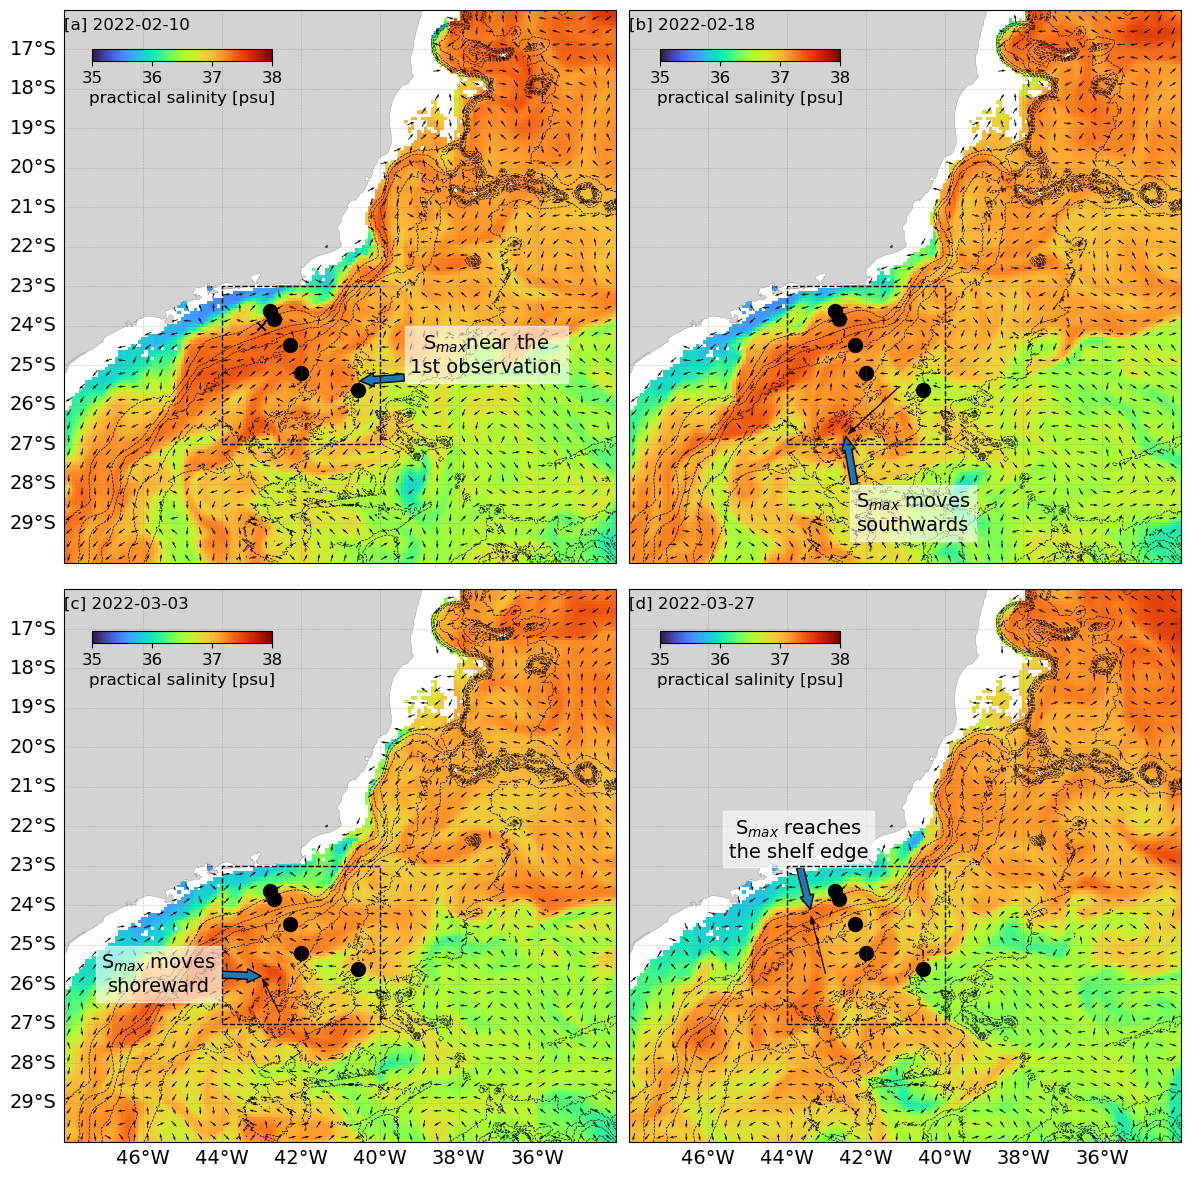

In [10]:
locations = {
    1: ([-41.1, -25.5],[-42.5, -26.8]),
    2: ([-42.5, -26.8],[-43., -25.8]),
    3: ([-43., -25.8],[-43.4, -24.2])
}

# locations for the glorys ts diagram
locs_glorys = {
    '2022-02-04': [-41, - 25.3], # OK
    # '2022-02-13': [-41.8, -26], # REMOVER?
    '2022-02-11': [-41.1, -25.5], # OK
    '2022-02-22': [-41.3, -26.8], # ok
    '2022-02-26': [-42.8, -26], # ok
    '2022-03-12': [-43, -25.2], # ok
    '2022-03-20': [-43.2, -24.5], # ok
    '2022-03-27': [-43., -24.] # ok
}

# arrows to point features of interest
dict_arrow = {
    '20220210': [(-40.5, -25.4),(-37.3, -25.2), r'S$_{max}$' + 'near the\n1st observation'],
    '20220218': [(-42.5, -26.8),(-40.8, -29.2), r'S$_{max}$' + ' moves\nsouthwards'],
    '20220303': [(-43., -25.8),(-45.6, -26.2), r'S$_{max}$' + ' moves\nshoreward'],
    '20220327': [(-43.4, -24.1),(-43.7, -22.8), r'S$_{max}$' +' reaches\nthe shelf edge'],
}

vmin,vmax = 35,38

quiver_kwargs = dict(scale=5, width=.0015, color='k', alpha=1, angles='xy', scale_units='xy', add_guide=False)
quiverkey=[-44.8, -18.6, 1, r'1 m s$^{-1}$']
quiverkey_kws=dict(labelpos='S', color='k', coordinates='data')

cbar_features = {
    '2022-02-10': [0.08, 0.94, 0.15, 0.01],
    '2022-02-18': [0.553, 0.94, 0.15, 0.01],
    '2022-03-03': [0.08, 0.455, 0.15, 0.01],
    '2022-03-27': [0.553, 0.455, 0.15, 0.01]
}

letters = 'a b c d'.split(' ')

# plotting the first observation, at Feb 10th (cast1)
values = dict_casts['cast1']
xlon = values['xlon']
ylat = values['ylat']

ntimes = ['2022-02-10', '2022-02-18', '2022-03-03', '2022-03-27']

# modified ylabel 
remove_ylabels_of = [1,3]
remove_xlabels_of = [0,1]

fig,axes = subplots_structure(2,2, (12,12), 4)

count = 0
for ax,ntime,letter in zip(axes, ntimes, letters):

    # default
    drawlinebottom=True
    drawlineleft=True
    drawlinetop=False
    drawlineright=False

    if count in remove_ylabels_of:
        drawlineleft=False   
    
    if count in remove_xlabels_of:
        drawlinebottom=False
       
    ax = make_map(ax=ax, extent=zoomed_extent, facecolor='lightgray', deltax=2, deltay=1,
                  drawlinebottom=drawlinebottom, drawlineleft=drawlineleft, 
                  drawlinetop=drawlinetop, drawlineright=drawlineright)
    
    ax.set_extent(zoomed_extent)

    ntime_search = datetime.strptime(ntime, '%Y-%m-%d').strftime('%Y-%m-%dT00:00:00.000000000')
    ds = dsall.sel(time=ntime_search)
    ds2 = ds.coarsen(longitude=4, latitude=4, boundary='pad').mean()
    
    spd = np.sqrt(ds2['uo']**2 + ds2['vo']**2)
    ds2['uo'] = ds2['uo'] / spd
    ds2['vo'] = ds2['vo'] / spd

    datestr = pd.to_datetime(ds.time.values).strftime('%Y-%m-%d')

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))
    
    pc = ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=vmin, vmax=vmax, add_colorbar=False)
    # cs = ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=[37.2], colors=['w'], linestyles=['--'])

    # PLOTTING EKMAN TRANSPORT   
    _ = ds2.isel(depth=idz).squeeze().plot.quiver(ax=ax, 
                        x='longitude', y='latitude', 
                        u='uo', v='vo',
                        **quiver_kwargs)

    for cast,values in dict_casts.items():
        prof = values['prof'] #keys[c]
        xlon = prof.attrs['lon']
        ylat = prof.attrs['lat']
        ax.scatter(xlon, ylat, c='k', s=100)
    
    cax = fig.add_axes(cbar_features[ntime])
    cbar = fig.colorbar(pc, cax=cax, orientation='horizontal')#, format=tkr.FormatStrFormatter('%d'))
    cbar.ax.tick_params(axis='x', labelsize=12)
    cbar.set_label('practical salinity [psu]', fontsize=12)
    _ = [ax.set_title('') for ax in axes]
    # _ = ax.set_title(f'GLORYS12V1, 50-m depth layer\n{datestr}', loc='left', fontsize=16, y=0.93)
    # _ = ax.text(-44.2, -16.3, f'GLORYS12V1\n50-m depth layer: {datestr}', fontsize=12, ha='center', va='top')
    ax.set_title(f"[{letter}] {datestr}", loc='left', y=0.95)
   
    # draw rectangle over area of interest
    ax.add_patch(patches.Rectangle((-44, -27), 4, 4, linewidth=1, edgecolor='k', ls='--', facecolor='none', zorder=20))

    # checking squares to be plotted based on the date
    if pd.to_datetime(ds.time.values).strftime('%Y%m%d') in dict_arrow.keys():
        loc = dict_arrow[pd.to_datetime(ds.time.values).strftime('%Y%m%d')]
    
        t = ax.annotate(loc[2],xy=loc[0], xytext=loc[1],
                 arrowprops={"width": 5, "headwidth": 10, "headlength": 10},
                 horizontalalignment="center", fontsize=14)
        t.set_bbox(dict(facecolor='white', alpha=0.6, edgecolor='white'))
    
    # add location where TSprofiles were extracted
    if datetime.strptime(str(ds.time.values), '%Y-%m-%dT00:00:00.000000000').strftime('%Y-%m-%d') in locs_glorys.keys():
        xloc,yloc = locs_glorys[datetime.strptime(str(ds.time.values), '%Y-%m-%dT00:00:00.000000000').strftime('%Y-%m-%d')]
        axes[0].scatter(xloc,yloc, marker='x', c='k')

    # add arrows 
    if count in locations.keys():
        locs = locations[count]
        from matplotlib.patches import FancyArrowPatch
        
        # seta curva
        arrow = FancyArrowPatch(
            locs[0],
            locs[1],
            linestyle='--',
            arrowstyle='Simple,head_length=6,head_width=4,tail_width=0.5',
            linewidth=0.4,
            color='k'
        )        
        ax.add_patch(arrow)

    count += 1

plt.tight_layout()
# plt.subplots_adjust(wspace=0.2)
plt.savefig(f"../figures/manuscript/00_manuscript_glorys12v1_fields.png",
           dpi=150,
           bbox_inches='tight')

plt.show()

Supporting Information:

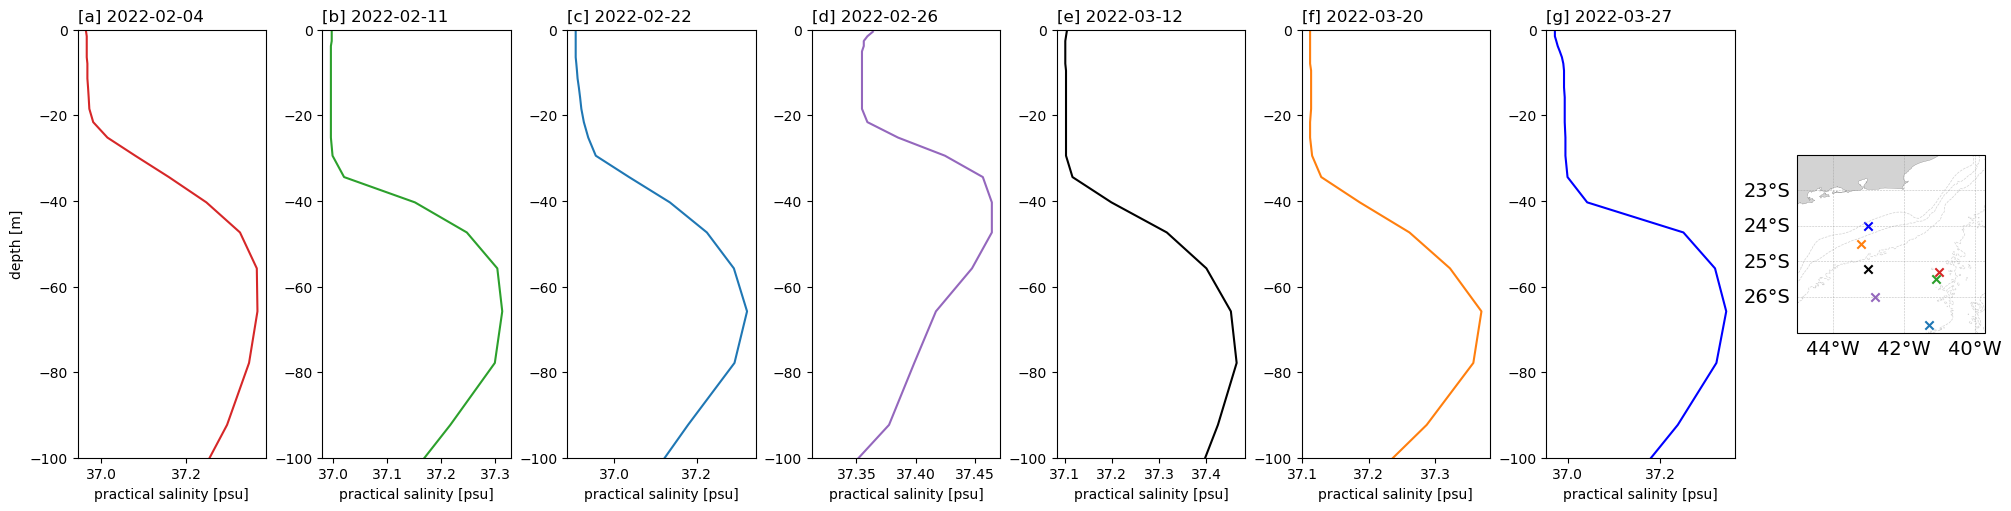

In [11]:
colors = ['tab:red', 'tab:green', 'tab:blue', 'tab:purple', 'k', 'tab:orange', 'blue']
import matplotlib.pyplot as plt

from matplotlib.gridspec import GridSpec

fig = plt.figure(layout="constrained", figsize=(20,5))

gs = GridSpec(1, 8, figure=fig)

ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])

ax4 = fig.add_subplot(gs[0,3])
ax5 = fig.add_subplot(gs[0,4])
ax6 = fig.add_subplot(gs[0,5])
ax7 = fig.add_subplot(gs[0,6])

axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7]
letters = 'a b c d e f g'.split(' ')
cont = 0
for k,item in locs_glorys.items():
    ax = axes[cont]
    letter = letters[cont]
    p = dsall.sel(time=k).sel(latitude=item[1], longitude=item[0], method='nearest')
    ax.plot(p['so'], p['depth']*(-1), c=colors[cont])
    ax.set_title(f"[{letter}] {k}", loc='left')
    ax.set_ylim([-100,0])
    # ax.set_xlim([36.7, 37.5])
    ax.set_xlabel('practical salinity [psu]')
    cont += 1

ax = fig.add_subplot(gs[0,-1], projection = ccrs.PlateCarree())
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent([-45, -39.7, -27, -22])

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -2000, -3000, -4000], 
                         colors=('lightgray'), linewidths=(0.5), linestyles=('--'))
cont = 0
for k,item in locs_glorys.items():
    ax.scatter(item[0], item[1], c=colors[cont], marker='x')
    cont += 1


ax1.set_ylabel('depth [m]')

plt.savefig(f"../figures/manuscript/glorys12v1_selected_train_profiles.png",
           dpi=150,
           bbox_inches='tight')

# ## TS
# fig,ax = plt.subplots()
# fig,ax = tsDiagram(fig=fig, ax=ax)

# cont = 0
# for k,item in locs_glorys.items():
#     p = dsall.sel(time=k).sel(latitude=item[1], longitude=item[0], method='nearest')
#     ax.scatter(p['so'], p['thetao'], label=k, c=colors[cont])
#     cont += 1
    
# plt.legend()
# _ = ax.set_xlim([36,38])
# _ = ax.set_ylim([20,30])

# plt.savefig(f"../figures/manuscript/glorys12v1_selected_tsdiagram.png",
#            dpi=150,
#            bbox_inches='tight')